Preparatory analysis on Wikipedia dataset, later built upon in Shared Word Analysis

- accessing the data
- analysing and cleaning it
- initial plot of shared words

In [2]:
from operator import index

import matplotlib.pyplot as plt
from datasets import load_dataset

af_ds = load_dataset("wikimedia/wikipedia", "20231101.af")
print(af_ds['train']['title'])

/Users/ninahew/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Column(['Afrika', 'Lys van Afrikaanse skrywers', 'Lys van Afrikaanse digters', 'Alice, Oos-Kaap', 'Australasië', ...])


In [3]:
nl_ds = load_dataset("wikimedia/wikipedia", "20231101.nl")
print(nl_ds['train']['title'])

Column(['Albert Speer', 'Andre Agassi', 'Groen (partij)', 'Anthony Fokker', 'Albert Plesman', ...])


In [4]:
print(af_ds)

DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'text'],
        num_rows: 112518
    })
})


In [94]:
af_ds

DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'text'],
        num_rows: 112518
    })
})

In [5]:
print(type(af_ds['train']['id']))

<class 'datasets.arrow_dataset.Column'>


In [6]:
print(af_ds['train']['id'][1])
print(type(af_ds['train']['id'][1]))

3
<class 'str'>


In [7]:
print(af_ds['train']['title'][1])
print(type(af_ds['train']['title'][1]))

Lys van Afrikaanse skrywers
<class 'str'>


In [8]:
print(af_ds['train']['text'][1])
print(type(af_ds['train']['text'][1]))

Hier volg 'n lys van Afrikaanse skrywers:

A 
 Berna Ackerman
 Willem Anker
 Hennie Aucamp

B 
 Eleanor Baker
 Margaret Bakkes
 Christine Barkhuizen le Roux
 Chris Barnard
 Mark Behr
 Pirow Bekker
 S.P. Benjamin
 Dricky Beukes
 Eugene Beukes
 Gerhard Beukes
 Lalie Beukes
 C.F. Beyers-Boshoff
 Albert Blake
 Stella Blakemore (Stella Owen)
 Helen Blackmore (mev. Bernard Lewis)
 Audrey Blignault
 Lynette Blignaut
 François Bloemhof
 Arnold Blumer
 Boerneef (Boplaas 1938)
 Louie Boshoff
 F.C.L. Bosman
 Herman Charles Bosman
 Annelie Botes
 Dina Botha
 Jaco Botha
 Lien Botha
 Susan Botha
 Tertia Botha
 Alba Bouwer
 Hendrik Brand (dr. S.H. Skaife)
 Johanna Brandt
 Lulu Brewis (Marietjie 1932)
 Breyten Breytenbach
 Kerneels Breytenbach
 André P. Brink
 Melt Brink
 N.J. Brummer
 Sannie Bruwer (Bodemvas 1929)
 Willie Burger

C 
 Analise Carstens
 Jan Lion Cachet (1854-1912)
 Jan F.E. Celliers
 J.D. Cilliers
 Abel Coetzee (Waarheen Vader? 1940)
 Elna Crouse
 Henk Crouse
 Christoffel Coetzee
 John

In [14]:
print(af_ds['train']['title'][0])
print(af_ds['train']['text'][0][0:500])

Afrika
Afrika

Afrika is die wêreld se tweede grootste kontinent (na Asië) in sowel oppervlakte as bevolking. Saam met die eilande beslaan dit ongeveer 30 221 532 km² wat 20,3% van die totale landoppervlakte van die aarde is en dit word bewoon deur meer as 1 miljard mense – ongeveer 'n sewende van die wêreldbevolking.

Lande

Tale 

Die meeste amptelike tale van Afrika is Indo-Europese tale soos Frans, Engels, Portugees, Spaans en Afrikaans.
 Frans: Benin, Burkina Faso, Burundi, Demokratiese Republiek 


In [13]:
print(nl_ds['train']['title'][0])
print(nl_ds['train']['text'][0][:500])

Albert Speer
Berthold Konrad Hermann Albert Speer (Mannheim, 19 maart 1905 – Londen, 1 september 1981) was een Duits architect en stedenbouwkundige. Tijdens de naziheerschappij over Duitsland (1933-1945) was hij vanaf 1937 rijksarchitect en vanaf 1942 rijksminister van Bewapening en Munitie. Door zijn vriendschap met Adolf Hitler en zijn ministerschap gold hij als een van de machtigste mannen van het Derde Rijk. Na de oorlog werd Speer in Neurenberg veroordeeld tot twintig jaar gevangenisstraf.

Voor 1933 
H


In [15]:
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.tokenize import PunktTokenizer

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/ninahew/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [19]:
test_entry_afrika = af_ds['train']['text'][0]
test_entry_al_speer = nl_ds['train']['text'][0]
# print(test_entry_afrika)
# print(test_entry_al_speer)

In [22]:
word_tokenize(test_entry_afrika)
word_tokenize(test_entry_al_speer)

['Berthold',
 'Konrad',
 'Hermann',
 'Albert',
 'Speer',
 '(',
 'Mannheim',
 ',',
 '19',
 'maart',
 '1905',
 '–',
 'Londen',
 ',',
 '1',
 'september',
 '1981',
 ')',
 'was',
 'een',
 'Duits',
 'architect',
 'en',
 'stedenbouwkundige',
 '.',
 'Tijdens',
 'de',
 'naziheerschappij',
 'over',
 'Duitsland',
 '(',
 '1933-1945',
 ')',
 'was',
 'hij',
 'vanaf',
 '1937',
 'rijksarchitect',
 'en',
 'vanaf',
 '1942',
 'rijksminister',
 'van',
 'Bewapening',
 'en',
 'Munitie',
 '.',
 'Door',
 'zijn',
 'vriendschap',
 'met',
 'Adolf',
 'Hitler',
 'en',
 'zijn',
 'ministerschap',
 'gold',
 'hij',
 'als',
 'een',
 'van',
 'de',
 'machtigste',
 'mannen',
 'van',
 'het',
 'Derde',
 'Rijk',
 '.',
 'Na',
 'de',
 'oorlog',
 'werd',
 'Speer',
 'in',
 'Neurenberg',
 'veroordeeld',
 'tot',
 'twintig',
 'jaar',
 'gevangenisstraf',
 '.',
 'Voor',
 '1933',
 'Het',
 'gezin',
 'waarin',
 'Speer',
 'werd',
 'geboren',
 ',',
 'was',
 'wat',
 'ze',
 'in',
 'het',
 'Duits',
 'noemen',
 'grossbürgerlich',
 ';',
 'in',

In [23]:
tokenized_afrika = word_tokenize(test_entry_afrika)
tokenized_al_speer = word_tokenize(test_entry_al_speer)

In [42]:
type(tokenized_afrika)
# list
len(tokenized_afrika)

3158

In [24]:
len(tokenized_al_speer)

3845

In [25]:
# Drop entries with character length <2 to remove punctuation and single letter abbreviations
tokenized_afrika_no_punc = [word for word in tokenized_afrika if len(word) > 2]
tokenized_al_speer_no_punc = [word for word in tokenized_al_speer if len(word) > 2]

In [29]:
len(tokenized_afrika_no_punc)

2335

In [30]:
len(tokenized_al_speer_no_punc)

2842

In [31]:
# Remove proper nouns (identified using upper case first letter)
tokenized_afrika_no_proper_nouns = [word for word in tokenized_afrika_no_punc if not word[0].isupper()]
tokenized_al_speer_no_proper_nouns = [word for word in tokenized_al_speer_no_punc if not word[0].isupper()]

In [33]:
print(len(tokenized_afrika_no_proper_nouns))

1940


In [34]:
print(len(tokenized_al_speer_no_proper_nouns))

2203


In [35]:
# Remove numerical values
tokenized_afrika_no_numbers = [word for word in tokenized_afrika_no_proper_nouns if not word.isnumeric()]
tokenized_al_speer_no_numbers = [word for word in tokenized_al_speer_no_proper_nouns if not word.isnumeric()]

In [55]:
print(len(tokenized_afrika_no_numbers))

1922


In [36]:
print(len(tokenized_al_speer_no_numbers))

2128


In [37]:
# Count all words in this corpus and add to dict

def generate_dictionary(tokenized_list):
    dictionary = {}
    for word in tokenized_list:
        if word not in dictionary:
            dictionary[word] = 0
        dictionary[word] +=1
    return dictionary

print(generate_dictionary(tokenized_afrika_no_numbers))

{'die': 292, 'wêreld': 6, 'tweede': 1, 'grootste': 13, 'kontinent': 3, 'sowel': 2, 'oppervlakte': 4, 'bevolking': 2, 'met': 15, 'eilande': 1, 'beslaan': 2, 'dit': 18, 'ongeveer': 3, 'km²': 2, 'wat': 42, '20,3': 1, 'van': 107, 'totale': 1, 'landoppervlakte': 2, 'aarde': 1, 'word': 27, 'bewoon': 1, 'deur': 20, 'meer': 6, 'miljard': 1, 'mense': 2, 'sewende': 1, 'wêreldbevolking': 1, 'meeste': 4, 'amptelike': 1, 'tale': 3, 'soos': 10, 'eSwatini': 1, 'tot': 14, 'hierdie': 2, 'daar': 13, 'ook': 12, 'verskillende': 1, 'gepraat': 1, 'onderverdeel': 1, 'hoogste': 4, 'punt': 2, 'seevlak': 2, 'laagste': 1, 'onder': 4, 'noorde': 3, 'terwyl': 6, 'rivier': 1, 'land': 1, 'volgens': 3, 'ruim': 1, 'miljoen': 2, 'derde': 2, 'vasteland': 6, 'ter': 4, 'ewenaar': 4, 'feitlik': 3, 'reëlreg': 1, 'helfte': 1, 'sny': 1, 'nou': 1, 'noord': 7, 'suid': 6, 'gesien': 2, 'sowat': 3, 'twee': 4, 'derdes': 1, 'landmassa': 3, 'deel': 12, 'deer\xaddes': 1, 'tussen': 8, 'maak': 2, 'mees': 2, 'tropiese': 7, 'alle': 1, 'vas

In [38]:
af_corpus = generate_dictionary(tokenized_afrika_no_numbers)
nl_corpus = generate_dictionary(tokenized_al_speer_no_numbers)

In [52]:
# Investigate overlap of shared words between corpora
import pandas as pd
af_df = pd.DataFrame.from_dict(af_corpus, orient='index', columns=['word_freq_af'])
nl_df = pd.DataFrame.from_dict(nl_corpus, orient='index', columns = ['word_freq_nl'])

af_df.head()

,word_freq_af
die,292
wêreld,6
tweede,1
grootste,13
kontinent,3


In [53]:
af_df.sort_values(by=['word_freq_af'], ascending = False)

,word_freq_af
die,292
van,107
wat,42
het,30
word,27
...,...
sterkste,1
reuse-bosvark,1
boseland,1
"20,3",1


In [54]:
nl_df.sort_values(by=['word_freq_nl'], ascending = False)


,word_freq_nl
van,152
het,79
een,75
zijn,45
hij,34
...,...
gute,1
truth,1
for,1
struggle,1


In [59]:
shared_words = pd.merge(af_df, nl_df, how = 'inner', left_index=True, right_index=True)

In [60]:
shared_words.shape

(79, 2)

In [81]:
shared_words.sort_values(by=['word_freq_nl'], ascending = False)

,word_freq_af,word_freq_nl
van,107,152
het,30,79
een,7,75
voor,1,31
was,2,30
...,...,...
grond,1,1
kort,1,1
beurt,1,1
goed,1,1


In [74]:
import seaborn as sns
import matplotlib.pyplot as plt

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_17670/979119816.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  compare_plot.set_xticklabels(compare_plot.get_xticklabels(), rotation=90)


[Text(0, 0, 'die'),
 Text(1, 0, 'grootste'),
 Text(2, 0, 'bevolking'),
 Text(3, 0, 'met'),
 Text(4, 0, 'dit'),
 Text(5, 0, 'km²'),
 Text(6, 0, 'wat'),
 Text(7, 0, 'van'),
 Text(8, 0, 'totale'),
 Text(9, 0, 'aarde'),
 Text(10, 0, 'meer'),
 Text(11, 0, 'tot'),
 Text(12, 0, 'daar'),
 Text(13, 0, 'ook'),
 Text(14, 0, 'onder'),
 Text(15, 0, 'volgens'),
 Text(16, 0, 'miljoen'),
 Text(17, 0, 'ter'),
 Text(18, 0, 'twee'),
 Text(19, 0, 'deel'),
 Text(20, 0, 'alle'),
 Text(21, 0, 'uit'),
 Text(22, 0, 'enkele'),
 Text(23, 0, 'kan'),
 Text(24, 0, 'aan'),
 Text(25, 0, 'hoe'),
 Text(26, 0, 'het'),
 Text(27, 0, 'waar'),
 Text(28, 0, 'was'),
 Text(29, 0, 'kon'),
 Text(30, 0, 'dat'),
 Text(31, 0, 'een'),
 Text(32, 0, 'huidige'),
 Text(33, 0, 'aantal'),
 Text(34, 0, 'vlak'),
 Text(35, 0, 'meter'),
 Text(36, 0, 'reeks'),
 Text(37, 0, 'lang'),
 Text(38, 0, 'vorm'),
 Text(39, 0, 'maar'),
 Text(40, 0, 'omdat'),
 Text(41, 0, 'hier'),
 Text(42, 0, 'bekend'),
 Text(43, 0, 'nog'),
 Text(44, 0, 'gebied'),
 Text(

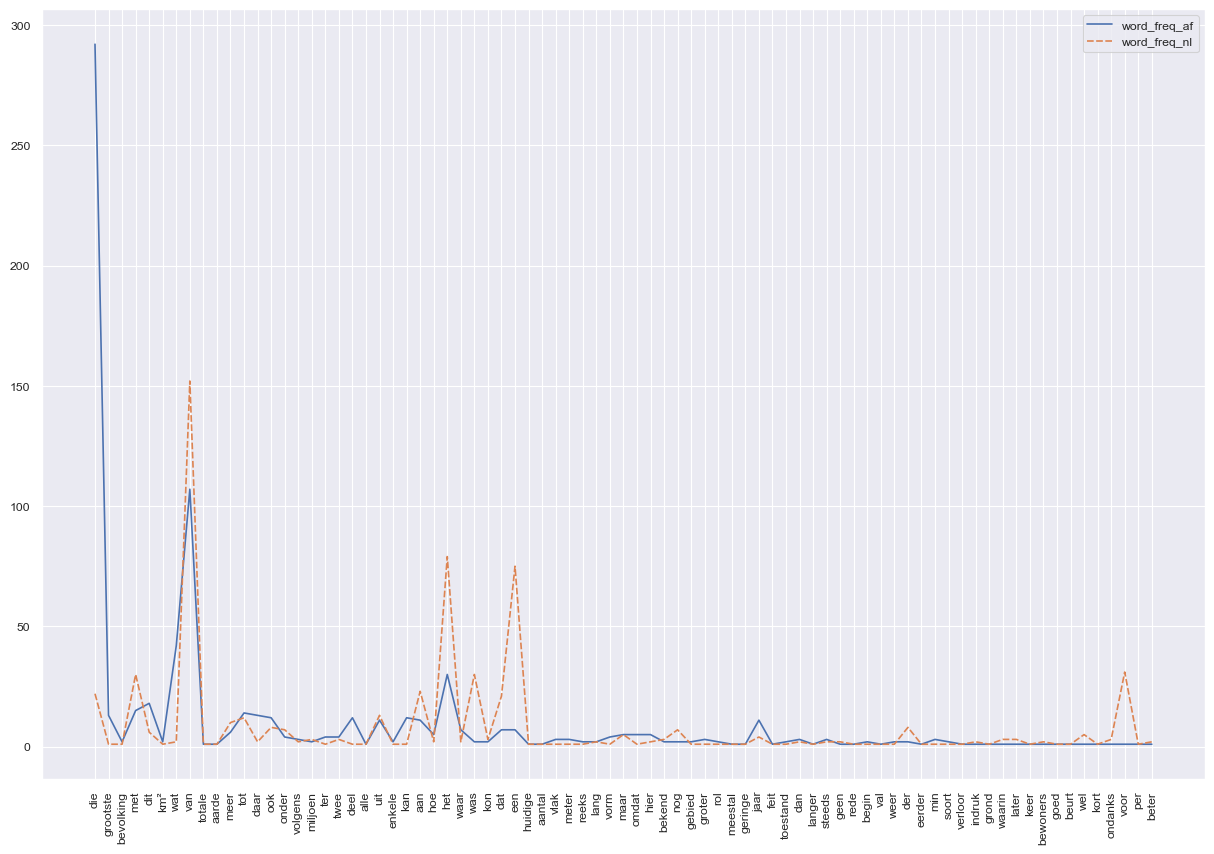

In [88]:
sns.set_theme(rc={'figure.figsize':(15,10)})
sns.set_theme(style="darkgrid", context="paper")
sns.color_palette("Spectral", as_cmap=True)


compare_plot = sns.lineplot(data = shared_words, sort = True)
# plt.setp(compare_plot.get_xticklabels(), rotation = 90)
compare_plot.set_xticklabels(compare_plot.get_xticklabels(), rotation=90)
